# 07 · The Prophet — Prompting a Decoder-only Language Model (DeepSeek)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Cecile1015/emotion-mirror-cbs4702/blob/main/notebooks/07_llm_deepseek.ipynb)

Every model of Steps 2–5 learned the task from the 16,000 labelled training texts: its parameters were fitted by minimising the cross-entropy between its predicted distribution and the gold labels. This notebook takes the opposite route. A large **decoder-only** language model, served by the DeepSeek API, is asked to classify the texts without any parameter update: the task is described in an **instruction** (zero-shot), optionally followed by a few labelled training texts placed in the prompt as **demonstrations** (few-shot). The model then generates the answer token by token.

| Model id | Task information given to the model | Parameters updated |
|---|---|---|
| `llm_zeroshot` | instruction only (best of three instructions on validation) | none |
| `llm_fewshot` | instruction + labelled training texts as demonstrations (best of four demonstration sets on validation) | none |
| `llm` | role name: the variant with the higher validation macro-F1 | |

**Protocol.**

* **Test subset.** 300 test texts drawn by stratified sampling (seed 42), so that every class keeps its share of the test split. All trained models are re-scored on exactly these 300 texts, which makes every comparison paired.
* **Prompt development** uses a separate stratified subset of 300 validation texts. Demonstrations are taken only from the training split. The test labels are used once, for the final scores of the two selected prompts.
* **Scoring.** The shared functions of `src/evaluate.py`; macro-F1 is the primary metric. Answers that cannot be mapped to one of the six emotions are counted as errors.

Questions answered here:

1. How well does an LLM classify the emotions without training, and how much do demonstrations add? (§5–6)
2. How does it compare with every trained model on the same texts, and which differences are significant? (§7)
3. Does it fail in a different way from the fine-tuned models? (§8)
4. What does each approach cost per prediction? (§9)
5. What explains the differences between prompting a decoder-only model and fine-tuning an encoder? (§10)

**Computation.** Every API response is stored in `results/llm/cache/`, keyed by a hash of the request. A re-run of the notebook reads the stored responses, so all numbers below are reproduced exactly without new API calls, although the remote model itself is not fully deterministic (§5.3).

## 0. Setup

In [1]:
# Environment setup: runs locally (from the project root or notebooks/) and on Google Colab.
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/Cecile1015/emotion-mirror-cbs4702.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # Colab provides the scientific packages; only the repository is cloned.
    ROOT = Path("/content/emotion-mirror-cbs4702")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
    os.chdir(ROOT / "notebooks")
else:
    ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()

sys.path.insert(0, str(ROOT))
print(f"Project root: {ROOT} | running on Colab: {IN_COLAB}")

Project root: /Users/yin/Desktop/6-polyu year3 semester1/CBS4702 Advanced Topics in Quantitative Language Studies/emotion-mirror-cbs4702 | running on Colab: False


In [2]:
import json
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy.stats import spearmanr
from sklearn.metrics import f1_score, log_loss
from sklearn.model_selection import train_test_split

from src.config import (
    DATA_DIR,
    EMOTION_COLORS,
    FIG_DIR,
    LABEL2ID,
    LABELS,
    METRICS_DIR,
    MODELS_DIR,
    NUM_LABELS,
    PRED_DIR,
    SEED,
    ensure_dirs,
    set_seed,
)
from src.data import load_splits, tokenize
from src.evaluate import evaluate, load_record, mcnemar_test, paired_bootstrap
from src.llm import (
    CACHE_DIR,
    INVALID_ID,
    LLM_DIR,
    PRICE_USD_PER_MILLION,
    STATUS_ORDER,
    DeepSeekClassifier,
    PromptSpec,
    estimate_cost,
    parse_label,
    probability_matrix,
    run_summary,
    save_prompt,
)
from src.slices import TEMPLATE_LEVELS, has_negation, template_slice

set_seed(SEED)
ensure_dirs()
LLM_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titleweight": "bold"})

CLASSICAL_DIR = MODELS_DIR / "classical"
LABEL_IDS = list(range(NUM_LABELS))
SUBSET_SIZE = 300
TEST_SPLIT = "test_subset300"  # split name used for every score on the test subset
VAL_SPLIT = "validation_subset300"


def savefig(fig, name):
    fig.savefig(FIG_DIR / name, bbox_inches="tight")


def macro_f1(y_true, y_pred):
    # Primary metric. An invalid answer (id -1) belongs to no class: it lowers the recall
    # of its true class and adds a false positive to no class.
    return f1_score(y_true, y_pred, labels=LABEL_IDS, average="macro", zero_division=0)


def bootstrap_ci(y_true, y_pred, n_boot=1000, seed=SEED):
    # Percentile 95% confidence interval of macro-F1 over resampled evaluation sets.
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    rng = np.random.default_rng(seed)
    n = len(y_true)
    scores = [macro_f1(y_true[idx], y_pred[idx]) for idx in (rng.integers(0, n, n) for _ in range(n_boot))]
    return np.percentile(scores, [2.5, 97.5])


def holm(p_values):
    # Holm step-down adjustment of a list of p-values (controls the family-wise error rate).
    p = np.asarray(p_values, dtype=float)
    order = np.argsort(p)
    adjusted = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adjusted[i] = min(1.0, running)
    return adjusted


client = DeepSeekClassifier()
print(f"requested model: {client.model} | API key available: {client.online} | "
      f"response cache: {CACHE_DIR.relative_to(ROOT)}")

requested model: deepseek-flash | API key available: True | response cache: results/llm/cache


## 1. Data and the fixed evaluation subsets

The subsets are drawn by **stratified sampling with proportional allocation**: each class contributes the same share of the subset as of its split (`train_test_split(..., stratify=y, random_state=42)`). A subset of 300 keeps the cost of the API calls small while the comparison with the trained models stays paired. Its limitation is the size of the minority classes: *surprise* is represented by about 10 texts, so per-class scores for *surprise* and *love* are much less precise than macro-F1 over all 300 texts.

In [3]:
splits = load_splits()
train, val, test = splits["train"], splits["validation"], splits["test"]
X_train, y_train = train["text"].tolist(), train["label"].to_numpy()
X_val, y_val = val["text"].tolist(), val["label"].to_numpy()
X_test, y_test = test["text"].tolist(), test["label"].to_numpy()


def stratified_subset(labels, n=SUBSET_SIZE, seed=SEED):
    """Row indices of a class-stratified random subset of size n (proportional allocation)."""
    idx, _ = train_test_split(np.arange(len(labels)), train_size=n, stratify=labels, random_state=seed)
    return np.sort(idx)


test_ids = stratified_subset(y_test)
val_ids = stratified_subset(y_val)
X_tsub, y_tsub = [X_test[i] for i in test_ids], y_test[test_ids]
X_vsub, y_vsub = [X_val[i] for i in val_ids], y_val[val_ids]

# The subsets are saved so that the web app and 08_error_analysis use the same texts.
for name, ids, X, y in [("test_subset300", test_ids, X_tsub, y_tsub), ("validation_subset300", val_ids, X_vsub, y_vsub)]:
    pd.DataFrame({"idx": ids, "text": X, "label": y, "label_name": [LABELS[i] for i in y]}).to_csv(
        LLM_DIR / f"{name}.csv", index=False)

composition = pd.DataFrame(index=LABELS)
for name, y in [("test", y_test), ("test subset", y_tsub), ("validation", y_val), ("validation subset", y_vsub)]:
    counts = np.bincount(y, minlength=NUM_LABELS)
    composition[f"{name}: n"] = counts
    composition[f"{name}: %"] = counts / counts.sum() * 100
composition.loc["total"] = composition.sum()
display(composition.style.format("{:.1f}", subset=[c for c in composition.columns if c.endswith("%")])
        .format("{:,.0f}", subset=[c for c in composition.columns if c.endswith(": n")]))

# Texts of the test subset that also occur verbatim in the training split (01_eda found 11 in the full test split).
train_set = set(X_train)
overlap = sum(t in train_set for t in X_tsub)
print(f"test-subset texts that also occur in the training split: {overlap}")

,test: n,test: %,test subset: n,test subset: %,validation: n,validation: %,validation subset: n,validation subset: %
sadness,581,29.0,87,29.0,550,27.5,82,27.3
joy,695,34.8,104,34.7,704,35.2,106,35.3
love,159,8.0,24,8.0,178,8.9,27,9.0
anger,275,13.8,41,13.7,275,13.8,41,13.7
fear,224,11.2,34,11.3,212,10.6,32,10.7
surprise,66,3.3,10,3.3,81,4.0,12,4.0
total,"2,000",100.0,300,100.0,"2,000",100.0,300,100.0


test-subset texts that also occur in the training split: 2


## 2. Classification as next-token prediction

**Decoder-only Transformer.** DeepSeek's chat models are stacks of Transformer **decoder** blocks. Each block applies *masked* (causal) multi-head self-attention, in which position $i$ may attend only to positions $j \le i$:

$$
\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}} + M\right)V, \qquad
M_{ij} = \begin{cases} 0 & j \le i \\ -\infty & j > i \end{cases}
$$

The model is pre-trained as a **language model**: it maximises the log-likelihood of every token given the tokens to its left,

$$
\log P_\theta(w_1, \dots, w_T) = \sum_{t=1}^{T} \log P_\theta(w_t \mid w_{<t}),
$$

and is then instruction-tuned to follow requests written in natural language. BERT (Step 5) is a stack of **encoder** blocks with no mask ($M = 0$): every token sees the whole sentence, and pre-training predicts masked words from both sides.

**Classification by generation.** The prompt — instruction $I$, demonstrations $D = \{(x_k, y_k)\}_{k=1}^{K}$ and the input text $x$ — is the left context, and the label is whatever the model generates next. With temperature 0, decoding is greedy:

$$
\hat{w}_t = \arg\max_{w \in \mathcal{V}} P_\theta(w \mid I, D, x, \hat{w}_{<t}).
$$

The output space is the whole token vocabulary $\mathcal{V}$, not the six classes, so the answer must be constrained (JSON mode) and validated (§3.2). The parameters $\theta$ are **frozen**: the demonstrations change the prediction only by conditioning, not by gradient descent. This is **in-context learning** (Brown et al., 2020). The fine-tuned classifiers of Steps 3–5 instead compute $P(y \mid x) = \text{softmax}(W\mathbf{h}_x + \mathbf{b})$ over exactly six classes, with $W$, $\mathbf{b}$ (and, for BERT, the encoder that produces $\mathbf{h}_x$) fitted to the 16,000 training labels.

## 3. The DeepSeek classifier

### 3.1 Request settings

The client in `src/llm.py` uses the OpenAI-compatible Chat Completions interface of DeepSeek.

| Setting | Value | Reason |
|---|---|---|
| Model | `deepseek-flash` (configurable) | DeepSeek's general-purpose low-cost chat model; the exact version that answered is recorded from every response |
| Thinking mode | disabled | the label is generated directly; a hidden reasoning trace would multiply output tokens and latency |
| Temperature | 0 | greedy decoding: the most probable token at every step |
| `response_format` | `{"type": "json_object"}` | JSON mode guarantees syntactically valid JSON, but not that the value is one of the six labels (§3.2) |
| `max_tokens` | 32 | the answer `{"label": "surprise"}` needs fewer than 10 tokens |
| `logprobs`, `top_logprobs` | true, 20 | log-probabilities of the 20 most likely tokens at each position → class probabilities (§8.4) |
| Concurrency, retries | 8 parallel requests; up to 5 retries with exponential back-off; 60 s timeout | rate-limit, server and connection errors are retried by the SDK |
| Cache | one JSON line per response in `results/llm/cache/<run>.jsonl` | exact reproduction of every number and no repeated cost |

The **cost** of a request is computed from the token counts that the API returns with each response. DeepSeek bills input tokens found in its prefix cache (*cache hit*) at a much lower rate than new input tokens (*cache miss*); because all requests of a run share the same instruction and demonstrations, most of a few-shot prompt is a cache hit after the first requests.

In [4]:
display(pd.Series(client.decoding_params(), name="value").to_frame())
display(pd.Series(PRICE_USD_PER_MILLION, name="USD per 1M tokens (list price)").to_frame())

,value
model,deepseek-flash
temperature,0.0
max_tokens,32
response_format,{'type': 'json_object'}
thinking,{'type': 'disabled'}


,USD per 1M tokens (list price)
cache_hit_input,0.006
cache_miss_input,0.300
output,1.200


### 3.2 Output validation

The generated text is mapped to a label by `parse_label` with fixed rules, and every answer receives a **status**:

| Status | Meaning | Scored as |
|---|---|---|
| `valid` | a JSON object whose `label` is exactly one of the six labels | that label |
| `normalised` | recovered by a fixed rule: different case or punctuation, a listed synonym (*happiness* → joy), another key name, or exactly one label word in non-JSON text | that label |
| `repaired` | the first answer was unusable; one corrective follow-up message produced a usable answer | that label |
| `invalid` | still unusable after the follow-up (empty, no label, several labels) | error (label id −1) |
| `api_error` | the request failed after all retries, e.g. refused by the provider's content filter | error (label id −1) |

Unusable answers are never replaced by a guess such as the majority class, because the model should not be credited for an answer it did not give. The tables report how many answers needed each step, so that a stricter reading (only `valid` answers) can be recomputed. The examples below show the parser on typical outputs.

In [5]:
examples = [
    '{"label": "joy"}', '{"label": "Joy"}', 'Sure! {"label": "fear"}', '{"emotion": "happiness"}',
    "The emotion is sadness.", '{"label": "neutral"}', "joy or love", "",
]
display(pd.DataFrame([{"raw output": repr(r), **vars(parse_label(r))} for r in examples]))

,raw output,label,status,detail
0,"'{""label"": ""joy""}'",joy,valid,
1,"'{""label"": ""Joy""}'",joy,normalised,label field 'Joy'
2,"'Sure! {""label"": ""fear""}'",fear,normalised,text around the JSON object
3,"'{""emotion"": ""happiness""}'",joy,normalised,label found under another key
4,'The emotion is sadness.',sadness,normalised,label word in non-JSON text
5,"'{""label"": ""neutral""}'",NaN,invalid,JSON without a usable label
6,'joy or love',NaN,invalid,"several labels: ['joy', 'love']"
7,'',NaN,invalid,empty output


## 4. Prompts

### 4.1 Zero-shot instructions

Three instructions of increasing specificity are compared on the validation subset (§5.1):

| Prompt id | Content |
|---|---|
| `zs_labels` | the task, the six label names and the output format |
| `zs_defined` | + a one-line definition of each emotion in everyday terms |
| `zs_lexicon` | + notes on the form of the texts and, for each emotion, the ten feeling words with the largest weight for that class in `improved_lr` (Step 3), which was fitted on the training split only |

The third instruction tests whether the **annotation convention** of the dataset can be communicated in words. Emotion datasets built from social-media posts often assign the label through the emotion word that the writer uses, and the words in the lexicon show that this convention does not always match everyday meaning.

In [6]:
INSTRUCTION = (
    "You are an emotion classifier for short English texts written by social-media users. "
    "Decide which emotion the writer expresses. Choose exactly one label from this list: "
    + ", ".join(LABELS) + ".\n"
    'Answer with a JSON object of the form {"label": "<label>"} and nothing else.'
)

DEFINITIONS = "\n".join([
    "Label definitions:",
    "- sadness: unhappiness, grief, loneliness, disappointment, hurt, feeling low or worthless.",
    "- joy: happiness, contentment, pride, relief, enthusiasm, feeling good, calm or confident.",
    "- love: affection, tenderness, caring, fondness, longing, romantic or sentimental warmth.",
    "- anger: irritation, annoyance, resentment, frustration, hostility, feeling wronged.",
    "- fear: anxiety, worry, nervousness, insecurity, feeling threatened, unsure or helpless.",
    "- surprise: amazement, astonishment, shock, curiosity, being impressed by something unexpected.",
])

# Cue words: the largest LR weights per class in improved_lr (TF-IDF unigrams, fitted on the training split).
improved_lr = joblib.load(CLASSICAL_DIR / "improved_lr.joblib")
vocab = np.array([name.split("__")[-1] for name in improved_lr[:-1].get_feature_names_out()])
coef = improved_lr[-1].coef_
EXPLICIT = {"fucked", "fucking", "horny", "shit", "shitty"}  # not placed in the prompt
cue_words = {}
for c, label in enumerate(LABELS):
    ranked = [w for w in vocab[np.argsort(-coef[c])] if w not in EXPLICIT]
    cue_words[label] = ranked[:10]
display(pd.DataFrame(cue_words).T.rename(columns=lambda j: j + 1))

LEXICON = "\n".join(
    [
        "Notes on the texts:",
        "- The texts are lower-cased and have no punctuation; contractions may appear as 'im', 'dont' or 'don t'.",
        "- Most texts report the writer's own feeling, often as 'i feel ...' or 'i am feeling ...'. "
        "When the writer names a feeling, let the named feeling word decide the label, "
        "even if the rest of the text suggests a different mood.",
        "- Feeling words that are typical of each label in this collection:",
    ]
    + [f"  - {label}: {', '.join(words)}" for label, words in cue_words.items()]
)

ZERO_SHOT = {
    "zs_labels": PromptSpec("zs_labels", INSTRUCTION, description="task, label names, output format"),
    "zs_defined": PromptSpec("zs_defined", INSTRUCTION + "\n\n" + DEFINITIONS, description="+ label definitions"),
    "zs_lexicon": PromptSpec("zs_lexicon", INSTRUCTION + "\n\n" + DEFINITIONS + "\n\n" + LEXICON,
                             description="+ notes on the texts and cue words from the training split"),
}
print(ZERO_SHOT["zs_lexicon"].system)

,1,2,3,4,5,6,7,8,9,10
sadness,lethargic,melancholy,punished,unfortunate,missed,disturbed,unwelcome,burdened,awkward,troubled
joy,superior,satisfied,innocent,sincere,divine,convinced,resolved,successful,pleasant,respected
love,sympathetic,caring,nostalgic,longing,naughty,tender,supportive,loving,hot,liked
anger,offended,resentful,dangerous,greedy,rude,irritable,distracted,rushed,dissatisfied,bothered
fear,pressured,terrified,shaken,reluctant,vulnerable,uncertain,paranoid,apprehensive,unsure,intimidated
surprise,impressed,amazed,curious,surprised,funny,shocked,dazed,overwhelmed,amazing,strange


You are an emotion classifier for short English texts written by social-media users. Decide which emotion the writer expresses. Choose exactly one label from this list: sadness, joy, love, anger, fear, surprise.
Answer with a JSON object of the form {"label": "<label>"} and nothing else.

Label definitions:
- sadness: unhappiness, grief, loneliness, disappointment, hurt, feeling low or worthless.
- joy: happiness, contentment, pride, relief, enthusiasm, feeling good, calm or confident.
- love: affection, tenderness, caring, fondness, longing, romantic or sentimental warmth.
- anger: irritation, annoyance, resentment, frustration, hostility, feeling wronged.
- fear: anxiety, worry, nervousness, insecurity, feeling threatened, unsure or helpless.
- surprise: amazement, astonishment, shock, curiosity, being impressed by something unexpected.

Notes on the texts:
- The texts are lower-cased and have no punctuation; contractions may appear as 'im', 'dont' or 'don t'.
- Most texts report the

### 4.2 Few-shot demonstrations

Demonstrations are passed as earlier turns of the conversation: the user sends a training text, and the assistant answers with its gold label in the target JSON format. The model thus sees the input format, the output format and the labelling convention before the test text.

**Selection rules** (training split only):

* Excluded: texts that also occur in the validation or test split (they would reveal the label of an evaluation text) and texts that occur more than once in the training split (01_eda found 30 duplicates with conflicting labels).
* Length between the 25th and 75th percentile of the training texts, so that demonstrations are typical.
* Two strategies: **random** (seed 42) and **prototypical** — the texts whose gold class receives the highest probability from `improved_lr`. These in-sample probabilities are optimistic, but they are used only for ranking, and they favour texts with an unambiguous cue word.
* $k \in \{1, 3\}$ demonstrations per class, i.e. 6 or 18 in total.
* Order: round-robin over the classes in a seeded random class order, so that the classes are interleaved; the class of the last demonstration matters most for some models (recency bias; Zhao et al., 2021).

The few-shot prompts reuse the instruction selected in §5.1.

In [7]:
lengths = np.array([len(tokenize(t)) for t in X_train])
q25, q75 = np.percentile(lengths, [25, 75])
eval_texts = set(X_val) | set(X_test)
counts = pd.Series(X_train).value_counts()
eligible = np.array([
    (t not in eval_texts) and counts[t] == 1 and q25 <= n <= q75
    for t, n in zip(X_train, lengths)
])
gold_proba = improved_lr.predict_proba(X_train)[np.arange(len(y_train)), y_train]
print(f"eligible training texts: {eligible.sum():,} of {len(X_train):,} (length {q25:.0f}-{q75:.0f} words)")


def select_demos(strategy, k, seed=SEED):
    """k demonstrations per class, interleaved over the classes."""
    rng = np.random.default_rng(seed)
    per_class = {}
    for c, label in enumerate(LABELS):
        pool = np.flatnonzero(eligible & (y_train == c))
        if strategy == "random":
            chosen = rng.choice(pool, size=k, replace=False)
        else:  # prototypical: highest gold-class probability under improved_lr
            chosen = pool[np.argsort(-gold_proba[pool])[:k]]
        per_class[label] = [X_train[i] for i in chosen]
    class_order = list(rng.permutation(LABELS))
    return tuple((per_class[label][j], label) for j in range(k) for label in class_order)


DEMO_SETS = {f"fs_{s}_k{k}": select_demos(s, k) for s in ("random", "proto") for k in (1, 3)}
display(pd.DataFrame(DEMO_SETS["fs_proto_k3"], columns=["demonstration text", "label"]))

eligible training texts: 8,122 of 16,000 (length 11-25 words)


,demonstration text,label
0,i feel so resentful and hateful and downright ...,anger
1,i feel accepted and respected i am loving loya...,love
2,i would be feeling i am genuinely shocked and ...,surprise
3,i am feeling terrified anxious excited and app...,fear
4,i practice being present and living in the now...,joy
5,i am so sick of feeling worthless and useless ...,sadness
6,i aint pissed angry mad or anything i just fee...,anger
7,i was flattered and i liked the feeling of bei...,love
8,i remembered seeing these pieces and feeling s...,surprise
9,i say that to myself when i am unsure or feeli...,fear


## 5. Prompt development on the validation subset

### 5.1 Stage A: zero-shot instruction

Each instruction classifies the 300 validation texts once. The instruction with the highest validation macro-F1 is kept (ties: the shorter prompt). The validation scores of the trained models on the same 300 texts are shown for reference.

In [8]:
def score_run(frame, y_true):
    pred = frame["pred"].to_numpy()
    lo, hi = bootstrap_ci(y_true, pred)
    return {"accuracy": float(np.mean(pred == y_true)), "macro-F1": macro_f1(y_true, pred),
            "95% CI": f"[{lo:.3f}, {hi:.3f}]"}


def tuning_row(prompt, frame, y_true, stage):
    s = run_summary(frame)
    return {"prompt": prompt.prompt_id, "stage": stage, "shots": prompt.n_shots, **score_run(frame, y_true),
            "not valid": s["n_normalised"] + s["n_repaired"] + s["n_invalid"] + s["n_api_error"],
            "unusable": s["n_invalid"] + s["n_api_error"],
            "input tokens / text": s["input tokens / text"], "cost (USD)": s["cost (USD)"]}


val_runs, tuning_rows = {}, []
for pid, prompt in ZERO_SHOT.items():
    val_runs[pid] = client.run(prompt, X_vsub, val_ids, run_name=f"validation__{pid}")
    tuning_rows.append(tuning_row(prompt, val_runs[pid], y_vsub, "A: zero-shot"))

stage_a = pd.DataFrame(tuning_rows).set_index("prompt")
best_zs_id = stage_a.sort_values(["macro-F1", "input tokens / text"], ascending=[False, True]).index[0]
display(stage_a.style.format({"accuracy": "{:.3f}", "macro-F1": "{:.4f}", "input tokens / text": "{:.0f}",
                              "cost (USD)": "{:.4f}"}))
print(f"selected zero-shot instruction: {best_zs_id}")

validation__zs_labels:   0%|          | 0/300 [00:00<?, ?it/s]

validation__zs_defined:   0%|          | 0/300 [00:00<?, ?it/s]

validation__zs_lexicon:   0%|          | 0/300 [00:00<?, ?it/s]

,stage,shots,accuracy,macro-F1,95% CI,not valid,unusable,input tokens / text,cost (USD)
prompt,,,,,,,,,
zs_labels,A: zero-shot,0,0.583,0.5250,"[0.457, 0.585]",0,0,109,0.0123
zs_defined,A: zero-shot,0,0.587,0.5302,"[0.463, 0.592]",4,0,228,0.0227
zs_lexicon,A: zero-shot,0,0.657,0.6220,"[0.555, 0.676]",1,0,475,0.0228


selected zero-shot instruction: zs_lexicon


### 5.2 Stage B: demonstrations

The selected instruction is combined with each of the four demonstration sets of §4.2.

In [9]:
best_instruction = ZERO_SHOT[best_zs_id].system
FEW_SHOT = {
    pid: PromptSpec(pid, best_instruction, demos=demos,
                    description=f"{best_zs_id} + {len(demos)} demonstrations ({pid.split('_')[1]})")
    for pid, demos in DEMO_SETS.items()
}
for pid, prompt in FEW_SHOT.items():
    val_runs[pid] = client.run(prompt, X_vsub, val_ids, run_name=f"validation__{pid}")
    tuning_rows.append(tuning_row(prompt, val_runs[pid], y_vsub, "B: few-shot"))

tuning = pd.DataFrame(tuning_rows).set_index("prompt")
stage_b = tuning[tuning["stage"] == "B: few-shot"]
best_fs_id = stage_b.sort_values(["macro-F1", "input tokens / text"], ascending=[False, True]).index[0]
PROMPTS = {**ZERO_SHOT, **FEW_SHOT}
selected = {"llm_zeroshot": best_zs_id, "llm_fewshot": best_fs_id}
role_llm = max(selected, key=lambda m: (tuning.loc[selected[m], "macro-F1"], -tuning.loc[selected[m], "input tokens / text"]))

# Validation scores of the trained models on the same 300 validation texts (saved predictions of Steps 2-5).
REFERENCE_VAL = ["tfidf_lr", "improved_lr", "bilstm", "bert"]
ref_val = {}
for m in REFERENCE_VAL:
    df = pd.read_csv(PRED_DIR / f"{m}__validation.csv")
    assert df["text"].tolist() == X_val, f"{m}__validation.csv is not aligned with the validation split"
    ref_val[m] = macro_f1(y_vsub, df["pred"].to_numpy()[val_ids])

tuning.to_csv(METRICS_DIR / "tuning_llm_validation.csv")
display(tuning.style.format({"accuracy": "{:.3f}", "macro-F1": "{:.4f}", "input tokens / text": "{:.0f}",
                             "cost (USD)": "{:.4f}"}))
print(f"selected: llm_zeroshot = {best_zs_id}, llm_fewshot = {best_fs_id}; role 'llm' = {role_llm}")
print("trained models, validation subset macro-F1: " + ", ".join(f"{m} {v:.3f}" for m, v in ref_val.items()))

validation__fs_random_k1:   0%|          | 0/300 [00:00<?, ?it/s]

validation__fs_random_k3:   0%|          | 0/300 [00:00<?, ?it/s]

validation__fs_proto_k1:   0%|          | 0/300 [00:00<?, ?it/s]

validation__fs_proto_k3:   0%|          | 0/300 [00:00<?, ?it/s]

,stage,shots,accuracy,macro-F1,95% CI,not valid,unusable,input tokens / text,cost (USD)
prompt,,,,,,,,,
zs_labels,A: zero-shot,0,0.583,0.5250,"[0.457, 0.585]",0,0,109,0.0123
zs_defined,A: zero-shot,0,0.587,0.5302,"[0.463, 0.592]",4,0,228,0.0227
zs_lexicon,A: zero-shot,0,0.657,0.6220,"[0.555, 0.676]",1,0,475,0.0228
fs_random_k1,B: few-shot,6,0.667,0.6378,"[0.571, 0.695]",0,0,664,0.0174
fs_random_k3,B: few-shot,18,0.690,0.6656,"[0.597, 0.722]",0,0,1025,0.0248
fs_proto_k1,B: few-shot,6,0.680,0.6531,"[0.586, 0.712]",0,0,631,0.0241
fs_proto_k3,B: few-shot,18,0.677,0.6459,"[0.579, 0.704]",0,0,977,0.0233


selected: llm_zeroshot = zs_lexicon, llm_fewshot = fs_random_k3; role 'llm' = llm_fewshot
trained models, validation subset macro-F1: tfidf_lr 0.917, improved_lr 0.915, bilstm 0.944, bert 0.950


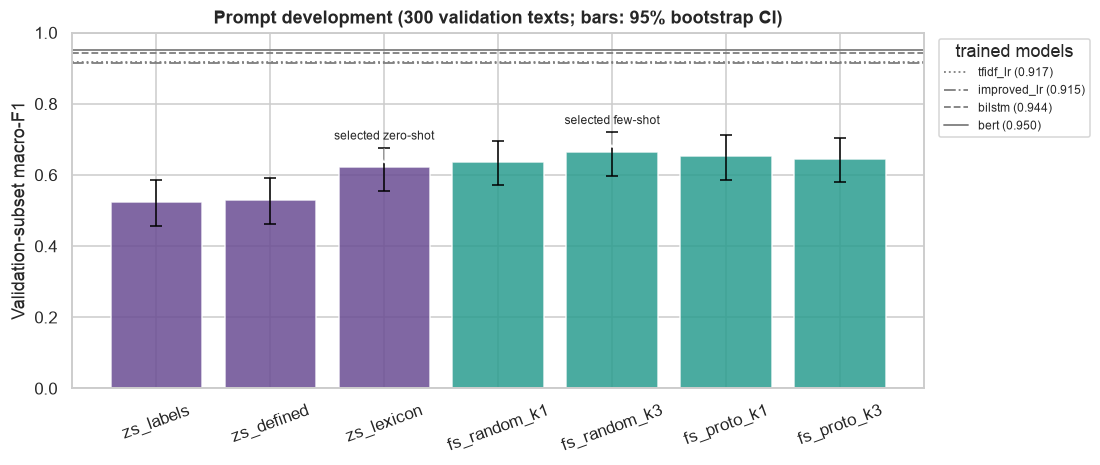

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.2))
order = tuning.index.tolist()
colors = ["#6A4C93" if tuning.loc[p, "stage"].startswith("A") else "#2A9D8F" for p in order]
ci = np.array([[float(x) for x in tuning.loc[p, "95% CI"].strip("[]").split(",")] for p in order])
values = tuning["macro-F1"].to_numpy()
ax.bar(order, values, color=colors, alpha=0.85)
ax.errorbar(order, values, yerr=[values - ci[:, 0], ci[:, 1] - values], fmt="none", ecolor="black", capsize=4, lw=1)
for m, style in zip(REFERENCE_VAL, [":", "-.", "--", "-"]):
    ax.axhline(ref_val[m], color="grey", ls=style, lw=1.2, label=f"{m} ({ref_val[m]:.3f})")
for p, marker in [(best_zs_id, "selected zero-shot"), (best_fs_id, "selected few-shot")]:
    ax.annotate(marker, (order.index(p), tuning.loc[p, "macro-F1"]), xytext=(0, 18), textcoords="offset points",
                ha="center", fontsize=8, arrowprops={"arrowstyle": "->", "lw": 0.8})
ax.set_ylim(0, 1)
ax.set_ylabel("Validation-subset macro-F1")
ax.set_title("Prompt development (300 validation texts; bars: 95% bootstrap CI)")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="trained models", fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
savefig(fig, "llm_prompt_development.png")
plt.show()

### 5.3 Run-to-run consistency

Temperature 0 makes the decoding greedy, but a remotely served model is not guaranteed to be deterministic: batching and floating-point non-associativity on the server can change a close decision between two tokens. Both selected prompts classify the validation subset a second time.

In [11]:
consistency_rows = []
for model_id, pid in selected.items():
    repeat = client.run(PROMPTS[pid], X_vsub, val_ids, run_name=f"validation__{pid}__repeat1", repeat=1)
    first = val_runs[pid]
    consistency_rows.append({
        "model": model_id, "prompt": pid,
        "same label in both runs": float(np.mean(first["pred"].to_numpy() == repeat["pred"].to_numpy())),
        "texts that changed": int(np.sum(first["pred"].to_numpy() != repeat["pred"].to_numpy())),
        "macro-F1 run 1": macro_f1(y_vsub, first["pred"]),
        "macro-F1 run 2": macro_f1(y_vsub, repeat["pred"]),
    })
consistency = pd.DataFrame(consistency_rows).set_index("model")
display(consistency.style.format({"same label in both runs": "{:.1%}", "macro-F1 run 1": "{:.4f}", "macro-F1 run 2": "{:.4f}"}))

validation__zs_lexicon__repeat1:   0%|          | 0/300 [00:00<?, ?it/s]

validation__fs_random_k3__repeat1:   0%|          | 0/300 [00:00<?, ?it/s]

,prompt,same label in both runs,texts that changed,macro-F1 run 1,macro-F1 run 2
model,,,,,
llm_zeroshot,zs_lexicon,98.3%,5,0.6220,0.6280
llm_fewshot,fs_random_k3,97.3%,8,0.6656,0.6682


In [12]:
zs_row, fs_row = tuning.loc[best_zs_id], tuning.loc[best_fs_id]
zs_scores = ", ".join(f"`{p}` {v:.3f}" for p, v in stage_a["macro-F1"].items())
fs_scores = ", ".join(f"`{p}` {v:.3f}" for p, v in tuning.loc[list(FEW_SHOT), "macro-F1"].items())
repeat_agreement = ", ".join(f"{v:.1%} ({m})" for m, v in consistency["same label in both runs"].items())
display(Markdown(f"""
**Reading of the validation results.**

* **Instruction.** Validation macro-F1: {zs_scores}; selected `{best_zs_id}`.
* **Demonstrations.** {fs_scores}; selected `{best_fs_id}`
  ({fs_row['macro-F1'] - zs_row['macro-F1']:+.3f} over the selected zero-shot prompt).
* **Trained models on the same texts.** BERT {ref_val['bert']:.3f}, BiLSTM {ref_val['bilstm']:.3f}, `improved_lr` {ref_val['improved_lr']:.3f}, `tfidf_lr` {ref_val['tfidf_lr']:.3f}.
* **Determinism.** A second run with the same prompt gives the same label for {repeat_agreement} of the texts.
* **Role `llm`.** `{role_llm}` (prompt `{selected[role_llm]}`), the variant with the higher validation macro-F1.
"""))


**Reading of the validation results.**

* **Instruction.** Validation macro-F1: `zs_labels` 0.525, `zs_defined` 0.530, `zs_lexicon` 0.622; selected `zs_lexicon`.
* **Demonstrations.** `fs_random_k1` 0.638, `fs_random_k3` 0.666, `fs_proto_k1` 0.653, `fs_proto_k3` 0.646; selected `fs_random_k3`
  (+0.044 over the selected zero-shot prompt).
* **Trained models on the same texts.** BERT 0.950, BiLSTM 0.944, `improved_lr` 0.915, `tfidf_lr` 0.917.
* **Determinism.** A second run with the same prompt gives the same label for 98.3% (llm_zeroshot), 97.3% (llm_fewshot) of the texts.
* **Role `llm`.** `llm_fewshot` (prompt `fs_random_k3`), the variant with the higher validation macro-F1.


## 6. Test evaluation on the 300-text subset

The two selected prompts classify the test subset once. The scores are saved through `src/evaluate.py` under the split name `test_subset300`; the predictions file additionally contains the status and the raw answer of each text. The selected prompts are saved in `results/llm/` so that the web application can reuse them.

In [13]:
test_runs, llm_preds, llm_proba, llm_records = {}, {}, {}, {}
for model_id, pid in selected.items():
    frame = client.run(PROMPTS[pid], X_tsub, test_ids, run_name=f"test__{pid}")
    test_runs[model_id] = frame
    llm_preds[model_id] = frame["pred"].to_numpy()
    llm_proba[model_id] = probability_matrix(frame)

for model_id in ["llm_zeroshot", "llm_fewshot", "llm"]:
    source = role_llm if model_id == "llm" else model_id
    frame, pid = test_runs[source], selected[source]
    notes = (f"DeepSeek {client.model} (served: {', '.join(sorted(frame['served_model'].dropna().unique()))}); "
             f"prompt {pid}; {PROMPTS[pid].n_shots} demonstrations; temperature 0; JSON mode; "
             f"stratified 300-text test subset (seed {SEED}); invalid answers scored as errors")
    llm_records[model_id] = evaluate(model_id, y_tsub, frame["pred"].to_numpy(), split=TEST_SPLIT,
                                     y_proba=llm_proba[source], texts=X_tsub, notes=notes)
    # Validation-subset scores of the selected prompts, for the summary table of the web app.
    evaluate(model_id, y_vsub, val_runs[pid]["pred"].to_numpy(), split=VAL_SPLIT, y_proba=probability_matrix(val_runs[pid]),
             texts=X_vsub, notes=notes.replace("test subset", "validation subset"), verbose=False)
    # Add the LLM-specific columns to the saved predictions.
    for split, run in [(TEST_SPLIT, frame), (VAL_SPLIT, val_runs[pid])]:
        path = PRED_DIR / f"{model_id}__{split}.csv"
        saved = pd.read_csv(path)
        saved["pred_label"] = run["pred_label"].to_numpy()  # "invalid" instead of an empty cell
        for col in ["status", "raw", "prompt_tokens", "completion_tokens", "latency_s"]:
            saved[col] = run[col].to_numpy()
        saved.to_csv(path, index=False)
    save_prompt(PROMPTS[pid], LLM_DIR / f"prompt_{model_id}.json")
llm_preds["llm"] = llm_preds[role_llm]
llm_proba["llm"] = llm_proba[role_llm]

all_llm_runs = {name: client.run(PROMPTS[name.split("__")[1]], X_vsub if name.startswith("validation") else X_tsub,
                                 val_ids if name.startswith("validation") else test_ids, run_name=name,
                                 repeat=1 if name.endswith("repeat1") else 0, progress=False)
                for name in sorted(p.stem for p in CACHE_DIR.glob("*.jsonl"))
                if name.split("__")[1] in PROMPTS}
served_models = sorted({m for f in all_llm_runs.values() for m in f["served_model"].dropna().unique()})
selection_info = {
    "requested_model": client.model, "served_models": served_models,
    "decoding": client.decoding_params(), "selected_prompts": selected, "role_llm": role_llm,
    "validation_macro_f1": {m: float(tuning.loc[p, "macro-F1"]) for m, p in selected.items()},
    "prices_usd_per_million_tokens": PRICE_USD_PER_MILLION,
    "total_cost_usd_all_runs": float(sum(estimate_cost(f) for f in all_llm_runs.values())),
}
(LLM_DIR / "selection.json").write_text(json.dumps(selection_info, indent=2))

validity = pd.DataFrame({m: run_summary(test_runs[m]) for m in selected}).T
display(validity[[f"n_{s}" for s in STATUS_ORDER] + ["input tokens / text", "cache-hit share", "cost (USD)",
                                                      "USD per 1,000 texts", "median latency (s)"]]
        .style.format(precision=3))
print(f"served model version(s): {', '.join(served_models)} | "
      f"estimated cost of all API runs in this notebook: US${selection_info['total_cost_usd_all_runs']:.3f}")

test__zs_lexicon:   0%|          | 0/300 [00:00<?, ?it/s]

test__fs_random_k3:   0%|          | 0/300 [00:00<?, ?it/s]

llm_zeroshot [test_subset300]  accuracy=0.7033  macro-F1=0.6616  weighted-F1=0.7087
llm_fewshot [test_subset300]  accuracy=0.7533  macro-F1=0.7129  weighted-F1=0.7529
llm [test_subset300]  accuracy=0.7533  macro-F1=0.7129  weighted-F1=0.7529


,n_valid,n_normalised,n_repaired,n_invalid,n_api_error,input tokens / text,cache-hit share,cost (USD),"USD per 1,000 texts",median latency (s)
llm_zeroshot,299.000,0.000,1.000,0.000,0.000,474.977,0.542,0.022,0.075,1.111
llm_fewshot,300.000,0.000,0.000,0.000,0.000,1025.207,0.787,0.024,0.079,1.103


served model version(s): deepseek-flash | estimated cost of all API runs in this notebook: US$0.238


## 7. All models on the same 300 texts

### 7.1 Re-evaluation of the trained models

The test predictions of every trained model were saved in `results/predictions/<model>__test.csv` (Steps 2–5). Restricting them to the 300 subset rows gives exactly the predictions the models make on these texts; §7.2 confirms this by predicting the texts again with the saved models. The table also compares each model's macro-F1 on the subset with its macro-F1 on the full test split, as a check that the subset is representative.

In [14]:
TRAINED = {
    # model id: (step, description)
    "bow_nb": ("Step 2", "BoW + Multinomial NB"),
    "bow_lr": ("Step 2", "BoW + LR"),
    "tfidf_lr": ("Step 2", "TF-IDF + LR"),
    "improved_lr": ("Step 3", "TF-IDF (sublinear) + LR, class weights"),
    "ngram_lr": ("Step 3", "word + char n-gram TF-IDF + LR"),
    "ngram_lr_no_char": ("Step 3", "ablation: no char n-grams"),
    "ngram_lr_no_cw": ("Step 3", "ablation: no class weights"),
    "ngram_lr_no_bigram": ("Step 3", "ablation: no word bigrams"),
    "ngram_cnb": ("Step 3", "n-gram TF-IDF + Complement NB"),
    "glove_twitter_lr": ("Step 4", "GloVe Twitter mean + LR"),
    "glove_wiki_lr": ("Step 4", "GloVe Wikipedia mean + LR"),
    "bilstm_frozen": ("Step 4", "BiLSTM, frozen GloVe"),
    "bilstm_finetuned": ("Step 4", "BiLSTM, fine-tuned GloVe"),
    "bert_frozen": ("Step 5", "BERT frozen, [CLS] + linear"),
    "bert_frozen_mean": ("Step 5", "BERT frozen, token mean + linear"),
    "bert_finetuned": ("Step 5", "BERT fine-tuned"),
}
ROLES = {"glove_lr": "glove_wiki_lr", "bilstm": "bilstm_finetuned", "bert": "bert_finetuned"}  # role -> selected variant
DISPLAY = {m: d for m, (_, d) in TRAINED.items()} | {
    "glove_lr": "GloVe + LR [selected]", "bilstm": "BiLSTM [selected]", "bert": "BERT [selected]",
    "llm_zeroshot": "DeepSeek zero-shot", "llm_fewshot": "DeepSeek few-shot", "llm": "DeepSeek [selected]",
}

saved_full, preds, proba = {}, {}, {}
for m in list(TRAINED) + list(ROLES):
    df = pd.read_csv(PRED_DIR / f"{m}__test.csv")
    assert df["text"].tolist() == X_test, f"{m}__test.csv is not aligned with the test split"
    saved_full[m] = df
    sub = df.iloc[test_ids]
    preds[m] = sub["pred"].to_numpy()
    pcols = [f"p_{c}" for c in LABELS]
    proba[m] = sub[pcols].to_numpy() if set(pcols) <= set(df.columns) else None
    evaluate(m, y_tsub, preds[m], split=TEST_SPLIT, y_proba=proba[m], texts=X_tsub,
             notes=f"saved test predictions of {m}, restricted to the stratified 300-text test subset (seed {SEED})",
             verbose=False)
for role, variant in ROLES.items():
    assert np.array_equal(preds[role], preds[variant]), f"{role} differs from {variant}"
preds.update(llm_preds)
proba.update(llm_proba)

rows = []
for m in list(TRAINED) + ["llm_zeroshot", "llm_fewshot"]:
    lo, hi = bootstrap_ci(y_tsub, preds[m])
    full = load_record(m, "test")["macro_f1"] if m in TRAINED else np.nan
    rows.append({"model": m, "step": TRAINED[m][0] if m in TRAINED else "Step 6", "description": DISPLAY[m],
                 "accuracy": float(np.mean(preds[m] == y_tsub)), "macro-F1": macro_f1(y_tsub, preds[m]),
                 "95% CI": f"[{lo:.3f}, {hi:.3f}]", "macro-F1, full test (2,000)": full})
ledger = pd.DataFrame(rows).set_index("model")
ledger["subset − full"] = ledger["macro-F1"] - ledger["macro-F1, full test (2,000)"]
ledger.to_csv(METRICS_DIR / "ledger_test_subset300.csv")
display(ledger.sort_values("macro-F1", ascending=False).style.format(
    {"accuracy": "{:.3f}", "macro-F1": "{:.3f}", "macro-F1, full test (2,000)": "{:.3f}", "subset − full": "{:+.3f}"}, na_rep="—"))

trained_rows = ledger.loc[list(TRAINED)]
rho = spearmanr(trained_rows["macro-F1"], trained_rows["macro-F1, full test (2,000)"]).statistic
print(f"trained models: Spearman rank correlation subset vs full test = {rho:.3f}; "
      f"mean |subset - full| = {trained_rows['subset − full'].abs().mean():.3f}")

,step,description,accuracy,macro-F1,95% CI,"macro-F1, full test (2,000)",subset − full
model,,,,,,,
bert_finetuned,Step 5,BERT fine-tuned,0.943,0.925,"[0.879, 0.963]",0.896,+0.029
bilstm_finetuned,Step 4,"BiLSTM, fine-tuned GloVe",0.937,0.895,"[0.836, 0.942]",0.894,+0.001
bilstm_frozen,Step 4,"BiLSTM, frozen GloVe",0.917,0.892,"[0.839, 0.934]",0.888,+0.005
ngram_lr,Step 3,word + char n-gram TF-IDF + LR,0.903,0.857,"[0.791, 0.911]",0.828,+0.029
ngram_lr_no_cw,Step 3,ablation: no class weights,0.900,0.847,"[0.782, 0.905]",0.819,+0.028
ngram_cnb,Step 3,n-gram TF-IDF + Complement NB,0.897,0.847,"[0.779, 0.901]",0.824,+0.022
ngram_lr_no_bigram,Step 3,ablation: no word bigrams,0.897,0.846,"[0.783, 0.901]",0.833,+0.013
improved_lr,Step 3,"TF-IDF (sublinear) + LR, class weights",0.890,0.840,"[0.775, 0.893]",0.843,-0.003
tfidf_lr,Step 2,TF-IDF + LR,0.893,0.836,"[0.768, 0.892]",0.832,+0.004


trained models: Spearman rank correlation subset vs full test = 0.871; mean |subset - full| = 0.020


### 7.2 Reproduction check and local inference time

The saved models are loaded again and predict the 300 texts. Identical labels confirm that §7.1 scores the models as they are deployed; the time per text is the local inference cost used in §9. Models whose files are not available on this machine (the GloVe tables, the BERT weights) are reported as skipped.

In [15]:
def time_predict(fn, texts):
    t0 = time.perf_counter()
    out = fn(texts)
    return out, (time.perf_counter() - t0) / len(texts) * 1000


checks = []
glove_ready = all((DATA_DIR / "embeddings" / f"{v}.vectors.npy").exists() for v in ("twitter200", "wiki300"))
for m in ["bow_nb", "bow_lr", "tfidf_lr", "improved_lr", "ngram_lr", "glove_twitter_lr", "glove_wiki_lr"]:
    if m.startswith("glove") and not glove_ready:
        checks.append({"model": m, "status": "skipped (GloVe cache not present)"})
        continue
    pipe = joblib.load(CLASSICAL_DIR / f"{m}.joblib")
    fresh, ms = time_predict(pipe.predict, X_tsub)
    checks.append({"model": m, "status": "checked", "identical labels": bool(np.array_equal(fresh, preds[m])),
                   "ms per text": ms, "device": "cpu"})

try:
    import torch
    from src.bilstm import get_device as bilstm_device, load_checkpoint, predict_proba as bilstm_proba

    device = bilstm_device()
    model, vocab_lstm, _ = load_checkpoint(MODELS_DIR / "bilstm" / "bilstm.pt", device)
    bilstm_proba(model, vocab_lstm, X_tsub[:8], device)  # warm-up (first call compiles GPU kernels)
    fresh, ms = time_predict(lambda X: bilstm_proba(model, vocab_lstm, X, device).argmax(axis=1), X_tsub)
    checks.append({"model": "bilstm", "status": "checked", "identical labels": bool(np.array_equal(fresh, preds["bilstm"])),
                   "ms per text": ms, "device": str(device)})
except Exception as exc:
    checks.append({"model": "bilstm", "status": f"skipped ({type(exc).__name__})"})

try:
    from src.bert_infer import BERT_DIR, BertEmotionClassifier, has_weights

    if not has_weights(BERT_DIR):
        raise FileNotFoundError("weights not in models/bert/")
    bert_clf = BertEmotionClassifier(BERT_DIR)
    bert_clf.predict_proba(X_tsub[:8])  # warm-up
    fresh, ms = time_predict(lambda X: bert_clf.predict_proba(X).argmax(axis=1), X_tsub)
    checks.append({"model": "bert", "status": "checked", "identical labels": bool(np.array_equal(fresh, preds["bert"])),
                   "ms per text": ms, "device": str(bert_clf.device)})
except Exception as exc:
    checks.append({"model": "bert", "status": f"skipped ({type(exc).__name__}: {str(exc)[:60]})"})

checks = pd.DataFrame(checks, columns=["model", "status", "identical labels", "ms per text", "device"]).set_index("model")
display(checks.style.format({"ms per text": "{:.2f}"}, na_rep="—"))

W1112 22:39:24.948000 51022 .venv/lib/python3.11/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,status,identical labels,ms per text,device
model,,,,
bow_nb,checked,True,0.01,cpu
bow_lr,checked,True,0.00,cpu
tfidf_lr,checked,True,0.01,cpu
improved_lr,checked,True,0.01,cpu
ngram_lr,checked,True,0.06,cpu
glove_twitter_lr,checked,True,0.73,cpu
glove_wiki_lr,checked,True,0.51,cpu
bilstm,checked,True,0.18,mps
bert,checked,True,3.06,mps:0


### 7.3 Where the LLM stands

All models on the same 300 test texts, ordered by macro-F1, with 95% bootstrap intervals.

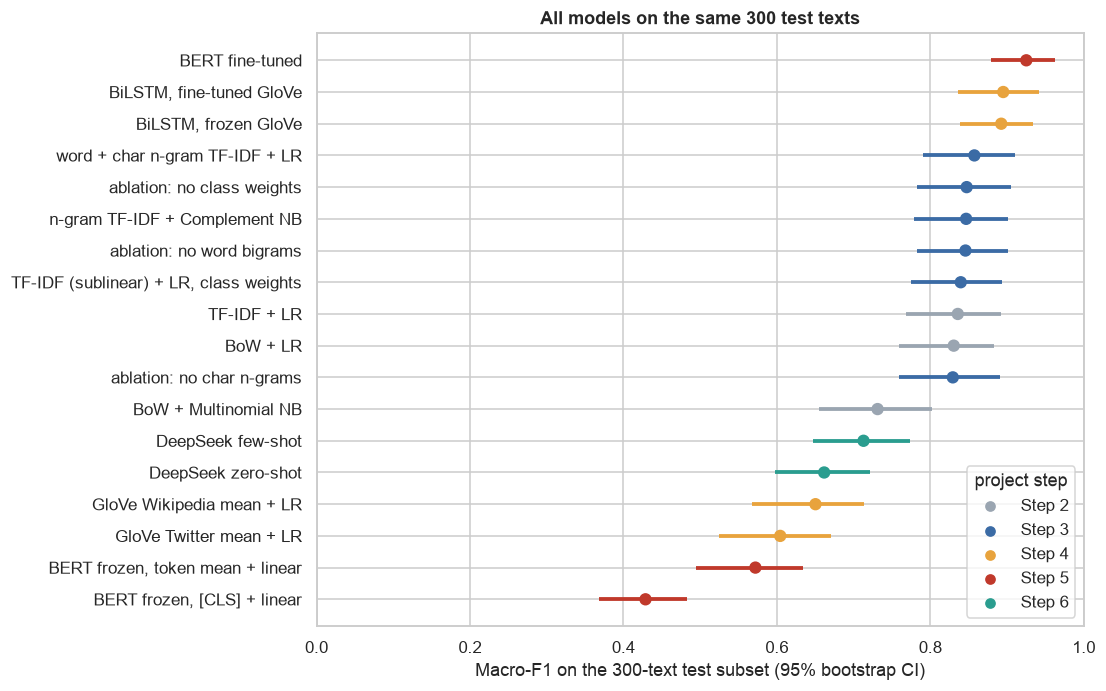

In [16]:
STEP_COLORS = {"Step 2": "#9AA5B1", "Step 3": "#3B6BA5", "Step 4": "#E8A33D", "Step 5": "#C0392B", "Step 6": "#2A9D8F"}
plot_df = ledger.sort_values("macro-F1")
ci = np.array([[float(x) for x in s.strip("[]").split(",")] for s in plot_df["95% CI"]])
fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(plot_df))
ax.hlines(y, ci[:, 0], ci[:, 1], color=[STEP_COLORS[s] for s in plot_df["step"]], lw=2.5)
ax.scatter(plot_df["macro-F1"], y, color=[STEP_COLORS[s] for s in plot_df["step"]], s=50, zorder=3)
ax.set_yticks(y, [f"{DISPLAY[m]}" for m in plot_df.index])
ax.set_xlabel("Macro-F1 on the 300-text test subset (95% bootstrap CI)")
ax.set_xlim(0, 1)
for step, color in STEP_COLORS.items():
    ax.scatter([], [], color=color, label=step)
ax.legend(loc="lower right", title="project step")
ax.set_title("All models on the same 300 test texts")
savefig(fig, "llm_ledger_subset.png")
plt.show()

### 7.4 Significance of the planned comparisons

McNemar's test on the texts where exactly one of two models is correct, and a paired bootstrap of the macro-F1 difference (2,000 resamples), Holm-adjusted over the six comparisons. With 300 texts the tests have less power than the 2,000-text comparisons of Steps 2–5: the confidence intervals are about 2.6 times wider, so a small difference may not be detected.

1. **Zero-shot → few-shot:** the effect of demonstrations (in-context learning).
2. **Zero-shot LLM → fine-tuned BERT** and 3. **selected LLM → fine-tuned BERT:** prompting a frozen decoder vs fine-tuning an encoder.
4. **Selected LLM → BiLSTM** (fine-tuned GloVe, Step 4).
5. **Selected LLM → `improved_lr`** (best sparse model, Step 3).
6. **`tfidf_lr` → selected LLM:** does the LLM beat the simplest strong baseline without any training?

In [17]:
COMPARISONS = [
    ("llm_zeroshot", "llm_fewshot"),
    ("llm_zeroshot", "bert"),
    ("llm", "bert"),
    ("llm", "bilstm"),
    ("llm", "improved_lr"),
    ("tfidf_lr", "llm"),
]
rows = []
for a, b in COMPARISONS:
    mc = mcnemar_test(y_tsub, preds[a], preds[b])
    bs = paired_bootstrap(y_tsub, preds[a], preds[b], n_boot=2000, seed=SEED)
    rows.append({
        "comparison (A → B)": f"{DISPLAY[a]} → {DISPLAY[b]}",
        "b (only A correct)": mc["b"], "c (only B correct)": mc["c"], "McNemar p": mc["p_value"],
        "Δ macro-F1 (B − A)": bs["delta"], "95% CI of Δ": f"[{bs['ci_low']:+.3f}, {bs['ci_high']:+.3f}]",
    })
significance = pd.DataFrame(rows).set_index("comparison (A → B)")
significance.insert(4, "Holm p", holm(significance["McNemar p"]))
significance.to_csv(METRICS_DIR / "significance_llm_test_subset300.csv")
display(significance.style.format({"McNemar p": "{:.2e}", "Holm p": "{:.2e}", "Δ macro-F1 (B − A)": "{:+.3f}"}))

,b (only A correct),c (only B correct),McNemar p,Δ macro-F1 (B − A),Holm p,95% CI of Δ
comparison (A → B),,,,,,
DeepSeek zero-shot → DeepSeek few-shot,4,19,2.60e-03,+0.051,2.60e-03,"[+0.001, +0.098]"
DeepSeek zero-shot → BERT [selected],4,76,2.05e-15,+0.263,1.23e-14,"[+0.204, +0.329]"
DeepSeek [selected] → BERT [selected],6,63,1.57e-11,+0.212,7.83e-11,"[+0.145, +0.284]"
DeepSeek [selected] → BiLSTM [selected],9,64,2.61e-10,+0.182,1.04e-09,"[+0.109, +0.263]"
"DeepSeek [selected] → TF-IDF (sublinear) + LR, class weights",15,56,2.06e-06,+0.127,5.63e-06,"[+0.054, +0.204]"
TF-IDF + LR → DeepSeek [selected],58,16,1.88e-06,-0.123,5.63e-06,"[-0.198, -0.049]"


### 7.5 Per-class scores and confusions

Confusion matrices are normalised by row (rows = gold label), so the diagonal is the recall of each class. For the LLM, an extra column counts the answers that could not be mapped to a label.

,DeepSeek zero-shot,DeepSeek few-shot,BiLSTM [selected],BERT [selected],support
sadness,0.795,0.820,0.971,0.982,87
joy,0.689,0.751,0.957,0.935,104
love,0.464,0.571,0.880,0.857,24
anger,0.741,0.747,0.937,0.952,41
fear,0.729,0.756,0.899,0.954,34
surprise,0.552,0.632,0.727,0.870,10


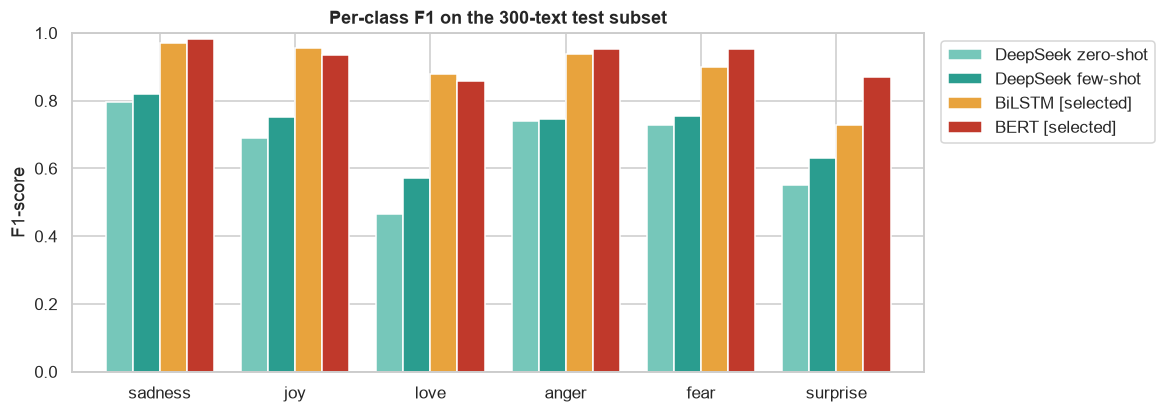

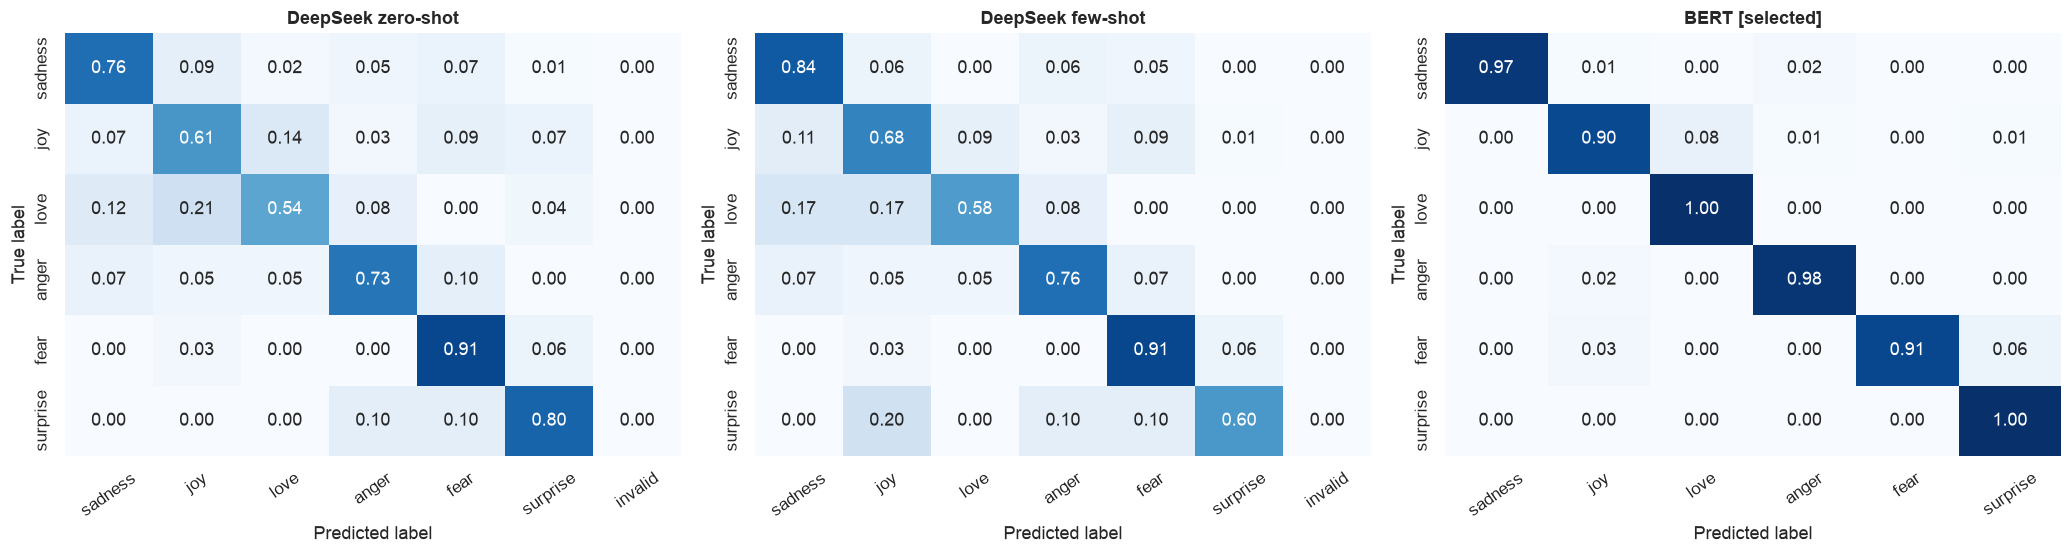

In [18]:
SHOW = ["llm_zeroshot", "llm_fewshot", "bilstm", "bert"]
pc = pd.DataFrame({
    DISPLAY[m]: f1_score(y_tsub, preds[m], labels=LABEL_IDS, average=None, zero_division=0) for m in SHOW
}, index=LABELS)
display(pc.assign(support=np.bincount(y_tsub, minlength=NUM_LABELS)).style.format("{:.3f}", subset=list(pc.columns)))

fig, ax = plt.subplots(figsize=(10, 4))
pc.plot(kind="bar", ax=ax, width=0.8, color=["#76C7BA", "#2A9D8F", "#E8A33D", "#C0392B"])
ax.set_ylim(0, 1)
ax.set_ylabel("F1-score")
ax.set_title("Per-class F1 on the 300-text test subset")
ax.tick_params(axis="x", rotation=0)
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
savefig(fig, "llm_per_class_f1.png")
plt.show()


def confusion_with_invalid(y_true, y_pred):
    # Rows: gold labels; columns: the six labels and "invalid"; each row sums to 1.
    cols = LABEL_IDS + [INVALID_ID]
    cm = np.array([[np.sum((y_true == i) & (y_pred == j)) for j in cols] for i in LABEL_IDS], dtype=float)
    return cm / cm.sum(axis=1, keepdims=True).clip(min=1)


fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
for ax, m in zip(axes, ["llm_zeroshot", "llm_fewshot", "bert"]):
    cm = confusion_with_invalid(y_tsub, preds[m])
    show_invalid = m.startswith("llm")
    data = cm if show_invalid else cm[:, :-1]
    sns.heatmap(data, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=LABELS + (["invalid"] if show_invalid else []), yticklabels=LABELS)
    ax.set_title(DISPLAY[m])
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
savefig(fig, "llm_confusion_matrices.png")
plt.show()

## 8. Does the LLM fail differently?

### 8.1 Predicted label distribution

A classifier trained with class weights on this dataset predicts the classes roughly in their gold proportions. A prompted model has no access to these proportions except through the demonstrations, so a systematic preference for some labels shows up directly in its prediction counts.

,sadness,joy,love,anger,fear,surprise,invalid
gold,87,104,24,41,34,10,0
DeepSeek zero-shot,79,79,32,40,51,19,0
DeepSeek few-shot,91,85,25,42,48,9,0
BERT [selected],84,97,32,43,31,13,0


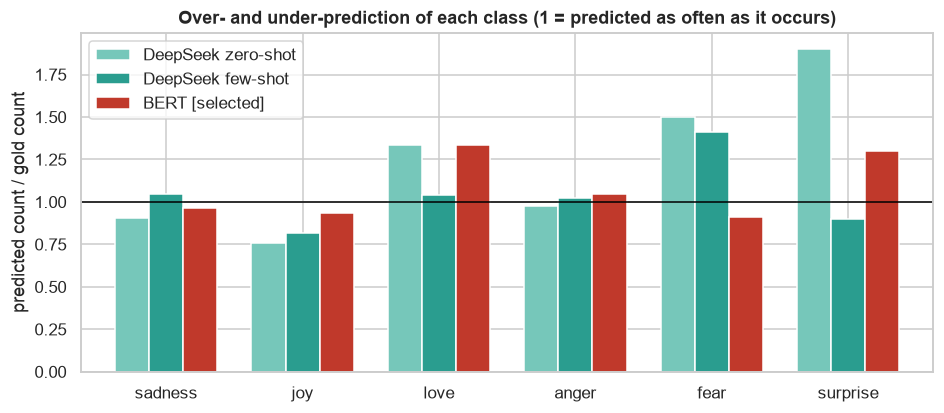

In [19]:
dist = pd.DataFrame({"gold": np.bincount(y_tsub, minlength=NUM_LABELS)}, index=LABELS)
for m in ["llm_zeroshot", "llm_fewshot", "bert"]:
    dist[DISPLAY[m]] = [int(np.sum(preds[m] == i)) for i in LABEL_IDS]
invalid_counts = {DISPLAY[m]: int(np.sum(preds[m] == INVALID_ID)) for m in ["llm_zeroshot", "llm_fewshot"]}
display(dist.T.assign(invalid=[0] + list(invalid_counts.values()) + [0]))

fig, ax = plt.subplots(figsize=(10, 4))
(dist.div(dist["gold"], axis=0)).drop(columns="gold").plot(kind="bar", ax=ax, width=0.75,
                                                           color=["#76C7BA", "#2A9D8F", "#C0392B"])
ax.axhline(1, color="black", lw=1)
ax.set_ylabel("predicted count / gold count")
ax.set_title("Over- and under-prediction of each class (1 = predicted as often as it occurs)")
ax.tick_params(axis="x", rotation=0)
savefig(fig, "llm_label_distribution.png")
plt.show()

### 8.2 Agreement and shared errors with BERT

If the LLM and BERT make the same mistakes, those texts are probably mislabelled or genuinely ambiguous; if their errors differ, the two approaches have learned different things.

In [20]:
llm_ok, bert_ok = preds["llm"] == y_tsub, preds["bert"] == y_tsub
agreement = pd.crosstab(pd.Series(np.where(llm_ok, "LLM correct", "LLM wrong"), name=""),
                        pd.Series(np.where(bert_ok, "BERT correct", "BERT wrong"), name=""))
display(agreement)
both_wrong = ~llm_ok & ~bert_ok
same_wrong = both_wrong & (preds["llm"] == preds["bert"])
print(f"same label from LLM and BERT: {np.mean(preds['llm'] == preds['bert']):.1%} of the texts | "
      f"both wrong: {both_wrong.sum()} | of these, same wrong label: {same_wrong.sum()}")

examples = pd.DataFrame({"text": X_tsub, "gold": [LABELS[i] for i in y_tsub],
                         "LLM": [LABELS[i] if i >= 0 else "invalid" for i in preds["llm"]],
                         "BERT": [LABELS[i] for i in preds["bert"]]})
rng = np.random.default_rng(SEED)
for title, mask in [("Only BERT correct", ~llm_ok & bert_ok), ("Only the LLM correct", llm_ok & ~bert_ok),
                    ("Both wrong", both_wrong)]:
    idx = np.flatnonzero(mask)
    display(Markdown(f"**{title}** ({len(idx)} texts; up to 8 shown)"))
    display(examples.iloc[np.sort(rng.choice(idx, size=min(8, len(idx)), replace=False))] if len(idx) else examples.iloc[[]])

,BERT correct,BERT wrong
,,
LLM correct,220,6
LLM wrong,63,11


same label from LLM and BERT: 74.7% of the texts | both wrong: 11 | of these, same wrong label: 4


**Only BERT correct** (63 texts; up to 8 shown)

,text,gold,LLM,BERT
44,i just feel are ludicrous and wasting space or...,surprise,anger,surprise
48,i also know what it feels like to be in a rela...,love,sadness,love
151,i feel like an idiot for trusting you though,joy,anger,joy
204,i felt a stronger wish to be free from self ch...,sadness,joy,sadness
223,i feel like my fish might be moderately more i...,joy,surprise,joy
231,i woke up and felt sad all over again but that...,joy,sadness,joy
260,i started to feel like i was going mad as i wa...,anger,fear,anger
284,im polyamorous something im starting to feel t...,love,joy,love


**Only the LLM correct** (6 texts; up to 8 shown)

,text,gold,LLM,BERT
70,i cant help feeling this way,sadness,sadness,joy
76,i feel about as helpless and superfluous as i ...,fear,fear,joy
105,getting sent on a company expense trip to anot...,joy,joy,anger
200,i feel his gracious presence even now,joy,joy,love
211,i already feel he is using us it feels weird b...,fear,fear,surprise
268,i feel so amazing musicjuzz,joy,joy,surprise


**Both wrong** (11 texts; up to 8 shown)

,text,gold,LLM,BERT
33,i hope everyone can help with charity work wit...,sadness,fear,anger
63,i began to feel very strange,fear,surprise,surprise
82,i feel like alcoholism is something that is wi...,joy,sadness,love
116,whenever i put myself in others shoes and try ...,anger,love,joy
140,i feel the need to pimp this since raini my be...,joy,love,love
233,i feel very cheated since i am supporting the ...,joy,anger,love
257,i have this grave feeling it will not be back ...,joy,sadness,love
267,i hate these feelings in my heart i hate that ...,sadness,anger,anger


### 8.3 Slices: the "feel" template and negation

The slices of `01_eda` (shared definitions in `src/slices.py`). The slice sizes are small, so the table is descriptive; the systematic behavioural tests follow in `08_error_analysis`.

In [21]:
template = template_slice(X_tsub)
negation = np.where(has_negation(X_tsub), "with negation cue", "without negation cue")
slice_rows = []
for name, values, levels in [("template", template, TEMPLATE_LEVELS),
                             ("negation", negation, ["without negation cue", "with negation cue"])]:
    for level in levels:
        mask = values == level
        row = {"slice": name, "level": level, "n": int(mask.sum())}
        row.update({DISPLAY[m]: float(np.mean(preds[m][mask] == y_tsub[mask])) for m in ["llm_zeroshot", "llm_fewshot", "bilstm", "bert"]})
        slice_rows.append(row)
slice_table = pd.DataFrame(slice_rows).set_index(["slice", "level"])
display(Markdown("Accuracy per slice:"))
display(slice_table.style.format("{:.3f}", subset=slice_table.columns[1:]))

Accuracy per slice:

### 8.4 Confidence and calibration

For the LLM, the probability of each class is read from the top-20 log-probabilities at the position where the label is generated (`label_distribution` in `src/llm.py`): each candidate token is assigned to the label it begins, and the six values are renormalised. Answers without log-probabilities (unusable answers) receive a uniform distribution. Calibration is measured by the log-loss and the expected calibration error (ECE, 10 equal-width confidence bins) on the test subset. BERT and the BiLSTM use the probabilities saved in Steps 4–5 (before temperature scaling).

,log-loss,ECE,mean confidence,accuracy,wrong with confidence > 0.9
model,,,,,
DeepSeek zero-shot,3.972,0.429,0.781,0.703,76
DeepSeek few-shot,3.122,0.379,0.747,0.753,56
BiLSTM [selected],0.267,0.047,0.981,0.937,11
BERT [selected],0.153,0.038,0.975,0.943,5


llm_fewshot: probability mass of the six labels at the label position (before renormalising): median 1.0000


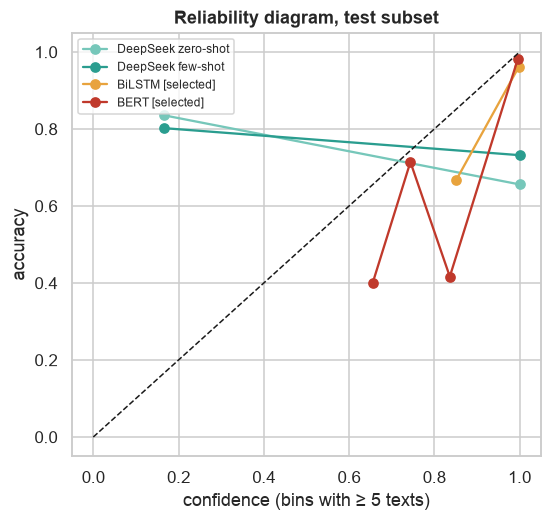

In [22]:
def expected_calibration_error(y_true, prob, n_bins=10):
    conf, pred = prob.max(axis=1), prob.argmax(axis=1)
    bins = np.minimum((conf * n_bins).astype(int), n_bins - 1)
    return float(sum(np.mean(bins == b) * abs(np.mean(pred[bins == b] == y_true[bins == b]) - conf[bins == b].mean())
                     for b in range(n_bins) if np.any(bins == b)))


calib_rows, calib_models = [], [m for m in ["llm_zeroshot", "llm_fewshot", "bilstm", "bert"] if proba.get(m) is not None]
for m in calib_models:
    p = np.clip(proba[m], 1e-6, 1)
    p = p / p.sum(axis=1, keepdims=True)
    wrong = preds[m] != y_tsub
    calib_rows.append({"model": DISPLAY[m], "log-loss": log_loss(y_tsub, p, labels=LABEL_IDS),
                       "ECE": expected_calibration_error(y_tsub, p), "mean confidence": float(p.max(axis=1).mean()),
                       "accuracy": float(np.mean(~wrong)), "wrong with confidence > 0.9": int(np.sum(wrong & (p.max(axis=1) > 0.9)))})
if calib_rows:
    calibration = pd.DataFrame(calib_rows).set_index("model")
    display(calibration.style.format({"log-loss": "{:.3f}", "ECE": "{:.3f}", "mean confidence": "{:.3f}", "accuracy": "{:.3f}"}))
    mass = test_runs[role_llm]["label_mass"]
    print(f"{role_llm}: probability mass of the six labels at the label position (before renormalising): "
          f"median {mass[mass > 0].median():.4f}")

    fig, ax = plt.subplots(figsize=(5.5, 5))
    edges = np.linspace(0, 1, 11)
    for m, color in zip(calib_models, ["#76C7BA", "#2A9D8F", "#E8A33D", "#C0392B"]):
        p = proba[m]
        conf, correct = p.max(axis=1), p.argmax(axis=1) == y_tsub
        idx = np.digitize(conf, edges[1:-1])
        xs = [conf[idx == b].mean() for b in range(10) if np.sum(idx == b) >= 5]
        ys = [correct[idx == b].mean() for b in range(10) if np.sum(idx == b) >= 5]
        ax.plot(xs, ys, "o-", color=color, label=DISPLAY[m])
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("confidence (bins with ≥ 5 texts)")
    ax.set_ylabel("accuracy")
    ax.set_title("Reliability diagram, test subset")
    ax.legend(fontsize=8)
    savefig(fig, "llm_reliability.png")
    plt.show()
else:
    print("The API returned no log-probabilities; calibration is not analysed.")

## 9. Cost and latency

The trained models are run locally; the times are those measured in §7.2 (batch prediction of 300 texts on this machine). The LLM cost is estimated from the token counts of the test-subset runs at the list prices of §3.1. API latency is measured per request and includes the network round trip; requests ran 8 at a time.

In [23]:
def local_ms(m):
    return checks.loc[m, "ms per text"] if m in checks.index else np.nan


training = {
    "improved_lr": "seconds on a laptop CPU",
    "bilstm": "about 16 minutes on the Mac GPU for six runs (05_bilstm)",
    "bert": "about 4.4 minutes per run on a Colab T4 GPU (06_bert)",
}
cost_rows = []
for m in ["improved_lr", "bilstm", "bert"]:
    cost_rows.append({"model": DISPLAY[m], "where it runs": "local", "task-specific training": training[m],
                      "labelled texts used": f"{len(X_train):,}", "latency per text (ms)": local_ms(m), "USD per 1,000 texts": 0.0})
for m in ["llm_zeroshot", "llm_fewshot"]:
    s = run_summary(test_runs[m])
    cost_rows.append({"model": DISPLAY[m], "where it runs": "remote API", "task-specific training": "none (prompt only)",
                      "labelled texts used": str(PROMPTS[selected[m]].n_shots),
                      "latency per text (ms)": s["median latency (s)"] * 1000, "USD per 1,000 texts": s["USD per 1,000 texts"]})
cost_table = pd.DataFrame(cost_rows).set_index("model")
cost_table.to_csv(METRICS_DIR / "cost_llm_vs_trained.csv")
display(cost_table.style.format({"latency per text (ms)": "{:.1f}", "USD per 1,000 texts": "{:.4f}"}, na_rep="—"))

,where it runs,task-specific training,labelled texts used,latency per text (ms),"USD per 1,000 texts"
model,,,,,
"TF-IDF (sublinear) + LR, class weights",local,seconds on a laptop CPU,"16,000",0.0,0.0000
BiLSTM [selected],local,about 16 minutes on the Mac GPU for six runs (05_bilstm),"16,000",0.2,0.0000
BERT [selected],local,about 4.4 minutes per run on a Colab T4 GPU (06_bert),"16,000",3.1,0.0000
DeepSeek zero-shot,remote API,none (prompt only),0,1111.0,0.0750
DeepSeek few-shot,remote API,none (prompt only),18,1103.1,0.0786


## 10. Discussion: prompting a decoder-only LLM vs fine-tuning

**Where the task knowledge lives.** A fine-tuned model stores what it learned from the 16,000 labelled texts in its parameters: gradient descent on the cross-entropy loss moves the weights of the classifier (and, for BERT, of the encoder) until the labels of the training split are predicted well. A prompted decoder-only model keeps its parameters fixed. Everything it knows about this particular task must pass through the context window — an instruction of a few hundred tokens and, at most, 18 demonstrations here — and act through causal self-attention on the next-token distribution. The LLM therefore brings very broad knowledge of language from pre-training, but almost no knowledge of this dataset.

**Label meaning vs annotation convention.** For a fine-tuned classifier the six labels are only indices $0, \dots, 5$; their meaning is whatever the training data assigns to them. For the LLM, the label names are words whose everyday meaning it already knows, and the instruction asks it to apply that meaning. The two meanings differ on this dataset: the cue words in §4.1 put *distracted* and *rushed* under anger, *overwhelmed* and *funny* under surprise and *superior* and *innocent* under joy. Such assignments are typical of corpora labelled through the emotion words that writers attach to their posts (distant supervision, as in Saravia et al., 2018). A fine-tuned model learns the convention from thousands of examples; a prompted model must be told, and the instruction variants (§5.1) and demonstration sets (§5.2) measure how much of the convention a prompt can transfer.

**Output space and reliability.** A classification head always outputs a distribution over exactly six classes. A generative model outputs text, so the answer must be constrained (JSON mode) and validated, and a small share of answers may still need repair or be unusable (§6). Requests can also fail for reasons outside the model, such as the provider's content filter.

**Probabilities.** The softmax of a classification head is trained, through the cross-entropy loss, to give probabilities for the six classes, and temperature scaling can calibrate it further (Steps 3–5). The token probabilities of an instruction-tuned LLM are next-token probabilities under the generation objective, reshaped by instruction tuning; nothing in their training makes them calibrated for this label set, and they can only be read when the API exposes them. §8.4 measures how well they match the accuracy here.

**Cost, latency and control.** The LLM needs no training data, no training run and no GPU on the user's side, which makes it the fastest model to set up. Each prediction, however, has a price and a network round trip, the input text leaves the machine, and the served model version can change over time (the version that answered is recorded in `results/llm/selection.json`). The fine-tuned models are free to run after training, fast and fully reproducible.

**A threat to validity: data contamination.** The dataset has been public with its labels since 2018. If its texts were part of the LLM's pre-training data, the LLM scores could be optimistic; this cannot be checked from the API. Any advantage of the LLM should therefore be read with caution, whereas a shortfall is unlikely to be caused by contamination.

The numbers behind these points are collected below.

In [24]:
sig = significance.reset_index().set_index("comparison (A → B)")


def sig_row(a, b):
    return sig.loc[f"{DISPLAY[a]} → {DISPLAY[b]}"]


def verdict(row):
    return "significant" if row["Holm p"] < 0.05 else "not significant"


def describe(a, b):
    r = sig_row(a, b)
    return (f"Δ macro-F1 {r['Δ macro-F1 (B − A)']:+.3f} {r['95% CI of Δ']}, McNemar {r['b (only A correct)']}/{r['c (only B correct)']}, "
            f"Holm p = {r['Holm p']:.1e} ({verdict(r)})")


def f(m, col="macro-F1"):
    return ledger.loc[m, col] if m in ledger.index else ledger.loc[ROLES.get(m, m), col]


pc_gap = (pc[DISPLAY["bert"]] - pc[DISPLAY[role_llm]]).iloc[:NUM_LABELS].sort_values(ascending=False)
s_role = run_summary(test_runs[role_llm])
calib_text = ""
if calib_rows:
    cal = calibration
    loglosses = ", ".join(f"{m} {v:.3f}" for m, v in cal["log-loss"].items())
    eces = ", ".join(f"{m} {v:.3f}" for m, v in cal["ECE"].items())
    role_cal = cal.loc[DISPLAY[role_llm]]
    calib_text = (f"* **Calibration.** Log-loss: {loglosses}. ECE: {eces}. Mean confidence of {DISPLAY[role_llm]} "
                  f"{role_cal['mean confidence']:.3f} at accuracy {role_cal['accuracy']:.3f}.")
zs_list = ", ".join(f"`{p}` {v:.3f}" for p, v in tuning.loc[list(ZERO_SHOT), "macro-F1"].items())
fs_list = ", ".join(f"`{p}` {v:.3f}" for p, v in tuning.loc[list(FEW_SHOT), "macro-F1"].items())
gap_list = ", ".join(f"{c} {d:+.3f}" for c, d in pc_gap.items())
same_label = np.mean(preds["llm"] == preds["bert"])

display(Markdown(f"""
### 11. Key results

The summary below is generated from the results of this run.

* **Prompt development (validation subset, macro-F1).** Zero-shot: {zs_list}. Few-shot: {fs_list}.
  Selected: `{best_zs_id}` and `{best_fs_id}`; role `llm` = `{role_llm}`. Served model: {', '.join(served_models)}.
* **Test subset (300 texts), macro-F1 [95% CI].** DeepSeek zero-shot {f('llm_zeroshot'):.3f} {ledger.loc['llm_zeroshot', '95% CI']},
  few-shot {f('llm_fewshot'):.3f} {ledger.loc['llm_fewshot', '95% CI']}; fine-tuned BERT {f('bert'):.3f} {f('bert', '95% CI')},
  BiLSTM {f('bilstm'):.3f}, `improved_lr` {f('improved_lr'):.3f}, `tfidf_lr` {f('tfidf_lr'):.3f}, `bow_nb` {f('bow_nb'):.3f}.
* **Representativeness of the subset.** Spearman ρ = {rho:.3f} between the subset and full-test macro-F1 of the 16 trained models.
* **Demonstrations:** {describe('llm_zeroshot', 'llm_fewshot')}.
* **Selected LLM → BERT:** {describe('llm', 'bert')}.
* **Zero-shot LLM → BERT:** {describe('llm_zeroshot', 'bert')}.
* **Selected LLM → BiLSTM:** {describe('llm', 'bilstm')}.
* **Selected LLM → improved_lr:** {describe('llm', 'improved_lr')}.
* **tfidf_lr → selected LLM:** {describe('tfidf_lr', 'llm')}.
* **Per-class F1, BERT − selected LLM:** {gap_list}.
* **Agreement with BERT.** Same label for {same_label:.1%} of the texts; {both_wrong.sum()} texts wrong for both, {same_wrong.sum()} of them with the same wrong label.
* **Answer validity ({role_llm}).** {s_role['n_valid']} valid, {s_role['n_normalised']} normalised, {s_role['n_repaired']} repaired,
  {s_role['n_invalid']} invalid, {s_role['n_api_error']} API errors out of {s_role['texts']}.
{calib_text}
* **Cost.** {s_role['input tokens / text']:.0f} input tokens per text ({s_role['cache-hit share']:.0%} cache hits),
  about US${s_role['USD per 1,000 texts']:.3f} per 1,000 texts; median latency {s_role['median latency (s)'] * 1000:.0f} ms per request.
  All API runs of this notebook: US${selection_info['total_cost_usd_all_runs']:.3f}.
"""))


### 11. Key results

The summary below is generated from the results of this run.

* **Prompt development (validation subset, macro-F1).** Zero-shot: `zs_labels` 0.525, `zs_defined` 0.530, `zs_lexicon` 0.622. Few-shot: `fs_random_k1` 0.638, `fs_random_k3` 0.666, `fs_proto_k1` 0.653, `fs_proto_k3` 0.646.
  Selected: `zs_lexicon` and `fs_random_k3`; role `llm` = `llm_fewshot`. Served model: deepseek-flash.
* **Test subset (300 texts), macro-F1 [95% CI].** DeepSeek zero-shot 0.662 [0.598, 0.722],
  few-shot 0.713 [0.647, 0.774]; fine-tuned BERT 0.925 [0.879, 0.963],
  BiLSTM 0.895, `improved_lr` 0.840, `tfidf_lr` 0.836, `bow_nb` 0.731.
* **Representativeness of the subset.** Spearman ρ = 0.871 between the subset and full-test macro-F1 of the 16 trained models.
* **Demonstrations:** Δ macro-F1 +0.051 [+0.001, +0.098], McNemar 4/19, Holm p = 2.6e-03 (significant).
* **Selected LLM → BERT:** Δ macro-F1 +0.212 [+0.145, +0.284], McNemar 6/63, Holm p = 7.8e-11 (significant).
* **Zero-shot LLM → BERT:** Δ macro-F1 +0.263 [+0.204, +0.329], McNemar 4/76, Holm p = 1.2e-14 (significant).
* **Selected LLM → BiLSTM:** Δ macro-F1 +0.182 [+0.109, +0.263], McNemar 9/64, Holm p = 1.0e-09 (significant).
* **Selected LLM → improved_lr:** Δ macro-F1 +0.127 [+0.054, +0.204], McNemar 15/56, Holm p = 5.6e-06 (significant).
* **tfidf_lr → selected LLM:** Δ macro-F1 -0.123 [-0.198, -0.049], McNemar 58/16, Holm p = 5.6e-06 (significant).
* **Per-class F1, BERT − selected LLM:** love +0.286, surprise +0.238, anger +0.205, fear +0.198, joy +0.184, sadness +0.162.
* **Agreement with BERT.** Same label for 74.7% of the texts; 11 texts wrong for both, 4 of them with the same wrong label.
* **Answer validity (llm_fewshot).** 300 valid, 0 normalised, 0 repaired,
  0 invalid, 0 API errors out of 300.
* **Calibration.** Log-loss: DeepSeek zero-shot 3.972, DeepSeek few-shot 3.122, BiLSTM [selected] 0.267, BERT [selected] 0.153. ECE: DeepSeek zero-shot 0.429, DeepSeek few-shot 0.379, BiLSTM [selected] 0.047, BERT [selected] 0.038. Mean confidence of DeepSeek few-shot 0.747 at accuracy 0.753.
* **Cost.** 1025 input tokens per text (79% cache hits),
  about US$0.079 per 1,000 texts; median latency 1103 ms per request.
  All API runs of this notebook: US$0.238.


### Implications for the project

* **Evaluation.** The LLM is evaluated on a 300-text subset; its scores are compared with the trained models only on the same texts (§7), never with their full-test scores.
* **Web application.** The fine-tuned models remain the main predictors: they run locally, are free per prediction, return calibrated probabilities and give the same answer every time. The LLM is best used as an optional third opinion with a clear label (remote, may change over time), with the selected prompt from `results/llm/prompt_llm.json`.
* **Error analysis.** The texts on which the LLM and the fine-tuned models disagree (§8.2) are candidates for the label-noise analysis of `08_error_analysis`: when an LLM that knows nothing of the annotation convention agrees with neither the gold label nor BERT, the text is often genuinely ambiguous.

## References

Brown, T. B., Mann, B., Ryder, N., Subbiah, M., Kaplan, J., Dhariwal, P., et al. (2020). Language models are few-shot learners. *Advances in Neural Information Processing Systems 33*, 1877–1901.

DeepSeek. (2026). *DeepSeek API documentation: Chat Completions, JSON output, context caching, models and pricing*. https://api-docs.deepseek.com

Devlin, J., Chang, M.-W., Lee, K., & Toutanova, K. (2019). BERT: Pre-training of deep bidirectional Transformers for language understanding. *Proceedings of NAACL-HLT 2019*, 4171–4186.

Dietterich, T. G. (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation*, 10(7), 1895–1923.

Guo, C., Pleiss, G., Sun, Y., & Weinberger, K. Q. (2017). On calibration of modern neural networks. *Proceedings of ICML 2017*, 1321–1330.

Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics*, 6(2), 65–70.

Min, S., Lyu, X., Holtzman, A., Artetxe, M., Lewis, M., Hajishirzi, H., & Zettlemoyer, L. (2022). Rethinking the role of demonstrations: What makes in-context learning work? *Proceedings of EMNLP 2022*, 11048–11064.

Ouyang, L., Wu, J., Jiang, X., Almeida, D., Wainwright, C. L., Mishkin, P., et al. (2022). Training language models to follow instructions with human feedback. *Advances in Neural Information Processing Systems 35*, 27730–27744.

Sainz, O., Campos, J. A., García-Ferrero, I., Etxaniz, J., Lopez de Lacalle, O., & Agirre, E. (2023). NLP evaluation in trouble: On the need to measure LLM data contamination for each benchmark. *Findings of EMNLP 2023*, 10776–10787.

Saravia, E., Liu, H.-C. T., Huang, Y.-H., Wu, J., & Chen, Y.-S. (2018). CARER: Contextualized affect representations for emotion recognition. *Proceedings of EMNLP 2018*, 3687–3697.

Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., & Polosukhin, I. (2017). Attention is all you need. *Advances in Neural Information Processing Systems 30*, 5998–6008.

Zhao, Z., Wallace, E., Feng, S., Klein, D., & Singh, S. (2021). Calibrate before use: Improving few-shot performance of language models. *Proceedings of ICML 2021*, 12697–12706.